In [1]:
import numpy as np
import pandas as pd
import requests
import scipy
from scipy.integrate import simpson
import matplotlib.pyplot as plt
import GenerateBNNModel as generate
import seaborn as sns

C:\Users\Grant\AppData\Local\Temp\ipykernel_17948\4209149419.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
first_name = 'Jalen'
last_name = 'Suggs'
middle_name= None
season=2024
days = 5

df_MA = generate.create_df_for_player(first_name, last_name, middle_name, days=days)

In [3]:
#Get average points
if middle_name == None:
        apiinfo = requests.get(f'http://127.0.0.1:5000/player_stats_for_season/first_name={first_name}/last_name={last_name}/season={season}')
else:
        apiinfo = requests.get(f'http://127.0.0.1:5000/player_stats_for_season/first_name={first_name}/last_name={last_name}/middle_name={middle_name}/season={season}')

data = apiinfo.json()

df_1 = pd.DataFrame.from_dict(data, orient='index')

columns_to_select = ['Minutes',
                        'Field Goals',
                        'Field Goal Attempts',
                        'Three Pointers',
                        'Three Point Attempts',
                        'Free Throws',
                        'Free Throw Attempts',
                        'Offensive Rebounds',
                        'Defensive Rebounds',
                        'Total Rebounds',
                        'Assists',
                        'Steals',
                        'Blocks',
                        'Turnovers',
                        'Fouls',
                        'Points']

#Get average points
if middle_name == None:
        apiinfo = requests.get(f'http://127.0.0.1:5000/player_stats_for_season/first_name={first_name}/last_name={last_name}/season={2025}')
else:
        apiinfo = requests.get(f'http://127.0.0.1:5000/player_stats_for_season/first_name={first_name}/last_name={last_name}/middle_name={middle_name}/season={2025}')

data = apiinfo.json()

df_2 = pd.DataFrame.from_dict(data, orient='index')

columns_to_select = ['Minutes',
                        'Field Goals',
                        'Field Goal Attempts',
                        'Three Pointers',
                        'Three Point Attempts',
                        'Free Throws',
                        'Free Throw Attempts',
                        'Offensive Rebounds',
                        'Defensive Rebounds',
                        'Total Rebounds',
                        'Assists',
                        'Steals',
                        'Blocks',
                        'Turnovers',
                        'Fouls',
                        'Points']

df = pd.concat([df_1, df_2])
df = df.reset_index().rename(columns={'index': 'Game Date'})

points = df['Points'].values

params = scipy.stats.skewnorm.fit(points)

x = np.linspace(0, 60, 6000)
prior = scipy.stats.skewnorm(*params)


In [4]:
df_features = df_MA[['Game Date', 'Average Points', 'Opponent Points']]
df_points = df[['Game Date', 'Points']]

final_df = df_points.merge(df_features, on='Game Date')

In [10]:
points_bins = np.arange(0, final_df['Points'].max()+2, 1)
avg_points_bins = np.arange(0, final_df['Average Points'].max()+2, 1)
avg_opponent_bins = np.arange(0, final_df['Opponent Points'].max()+2, 1)


final_df['Points Bin'] = pd.cut(final_df['Points'], bins=points_bins, labels=False, right=False)
final_df['Average Points Bin'] = pd.cut(final_df['Average Points'], bins=avg_points_bins, labels=False, right=False)
final_df['Opponent Points Bin'] = pd.cut(final_df['Opponent Points'], bins=avg_opponent_bins, labels=False, right=False)

avg_points_joint_distribution = pd.crosstab(final_df["Points Bin"], final_df["Average Points Bin"], dropna=False)
opponent_points_joint_distribution = pd.crosstab(final_df["Points Bin"], final_df["Opponent Points Bin"], dropna=False)

print(avg_points_joint_distribution)

Average Points Bin  6   7   8   9   10  11  12  13  14  15  16  17  18  19  20
Points Bin                                                                    
0                    0   0   0   0   1   0   0   1   0   0   0   0   0   0   0
2                    0   0   0   0   0   0   0   0   0   1   0   0   0   1   0
3                    0   0   0   0   1   0   0   0   0   0   0   0   0   0   0
4                    0   0   0   0   0   0   1   0   2   1   0   1   0   0   0
5                    0   0   0   0   0   0   0   0   0   1   0   0   0   0   0
6                    0   0   0   0   1   1   0   0   0   0   0   0   0   0   0
7                    0   1   0   0   0   2   0   1   0   0   0   1   0   0   0
8                    0   0   0   0   0   1   2   0   0   0   0   0   0   0   0
9                    0   0   1   0   1   0   0   1   0   2   0   1   0   0   0
10                   0   0   0   1   1   0   1   4   1   1   1   0   0   0   1
11                   0   0   1   2   2   2   0   0  

In [7]:
def solve_probability_stat(value, PMA, OMA, prior, avg_point_distribution, opponent_point_distribution):
    point_normalization_constant = sum(avg_point_distribution.sum())
    opponent_normalization_constant = sum(opponent_point_distribution.sum())
    p_A = prior.pdf(value)
    p_PMA = sum(avg_point_distribution.loc[:value, PMA])/point_normalization_constant
    p_OMA = sum(opponent_point_distribution.loc[:value, OMA])/opponent_normalization_constant

    return p_A * p_PMA * p_OMA


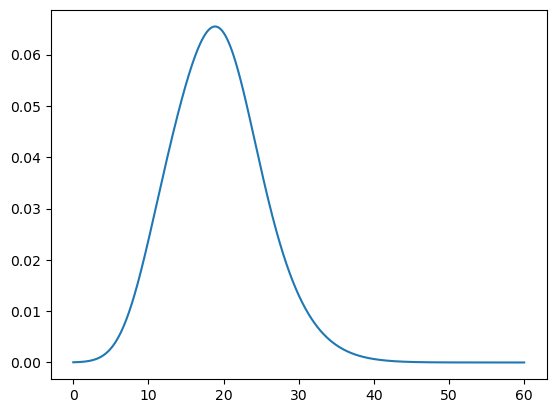

In [8]:
#This gives us the probability that the player scores less than or equal to 14 points given that they have a 13 point 5-day moving average
point_range = np.arange(0, 51, 1)
final_dist = np.zeros(len(point_range))
for i in range(len(final_dist)):
    final_dist[i] = solve_probability_stat(point_range[i], 20, 100, prior, avg_points_joint_distribution, opponent_points_joint_distribution)

final_dist = final_dist/sum(final_dist)

fitted_dist = scipy.stats.gaussian_kde(point_range, weights=final_dist)
smoothed_dist = fitted_dist(x)

plt.plot(x, smoothed_dist)
plt.show()
